# Chemical perturbation response prediction

**Yernur Kenzhegazin · Alan Berdigaliyev · Hugo Telles**  
M2 GENIOMHE-AI · Supervisor: Amaury Giard, IBISC

This notebook compares three MLP representations, derives the validation-preferred candidate from saved scores, examines its refinement and compares the refined ECFP4 MLP with retrained PRnet. Every predictor receives measured DMSO expression as input. The unchanged-DMSO reference directly copies that measured expression as the prediction and has no fitted weights.

This notebook follows the project questions: prediction for unseen compounds, transfer to SKBR3, external gene-regulation direction and sensitivity to control noise. It reads saved measurements and results, and includes a small checkpoint inference example. These evaluation sets were examined during development, so the findings remain exploratory.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Image

PROJECT = Path.cwd()
if not (PROJECT / 'extension/balanced').exists():
    raise FileNotFoundError('Open this notebook from the extracted project directory.')
BALANCED = PROJECT / 'extension/balanced'
sys.path.insert(0, str(PROJECT / 'extension'))
sys.path.insert(0, str(PROJECT / 'presentation'))
from focus_figures import SELECTED_MODELS, DISPLAY_MODELS, NAMES
MLP_CANDIDATES = ['ResidualFCFP4', 'Residual', 'ResidualChemicalVAE']
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__)

Python: 3.13.7
NumPy: 2.5.4 | pandas: 3.1.1


## 1. What the data and DMSO controls mean

Each row in the treated-expression file is a measured profile. The 978 gene columns contain normalized LINCS Level 3 expression values, not read counts, percentages or probabilities. The analysis uses 10 µM exposure for 24 hours.

DMSO is the vehicle used without the active compound. Controls are matched by detection plate, cell line, time and bead batch, then averaged separately for each gene. **DMSO expression therefore means 978 averaged measurements.** It is an input to each model, not a fifth network. Model inputs are standardized with training-only statistics; targets and the residual output remain on the original supplied scale.

The compound split and sample-usage files preserve the shared assignments. Screening removes ineligible rows equally for all representations. Extra fitted control-only, mean-response and linear models are documented separately in `docs/SUPPLEMENTARY_ANALYSES.md`.

In [2]:
audit = json.loads((BALANCED / 'generalization_audit.json').read_text())
verification = json.loads((BALANCED / 'verification.json').read_text())
display(pd.DataFrame({'profiles': audit['samples'], 'compounds': audit['compounds']}))
print('Integrity checks:', verification['status'])
print('Internal test profiles sharing a training control group:', audit['test_profiles_with_control_group_seen_in_train'])
print('Internal test compounds with a training analogue above 0.7:', audit['test_compounds_above_0_7_similarity_to_train'])
print('Test compounds with identical ECFP4 to training:', audit['test_compounds_with_identical_ECFP4_to_training'])

Integrity checks: passed
Internal test profiles sharing a training control group: 27752
Internal test compounds with a training analogue above 0.7: 545
Test compounds with identical ECFP4 to training: 295


,profiles,compounds
train,210438,8168
val,25190,1029
test,27765,1019


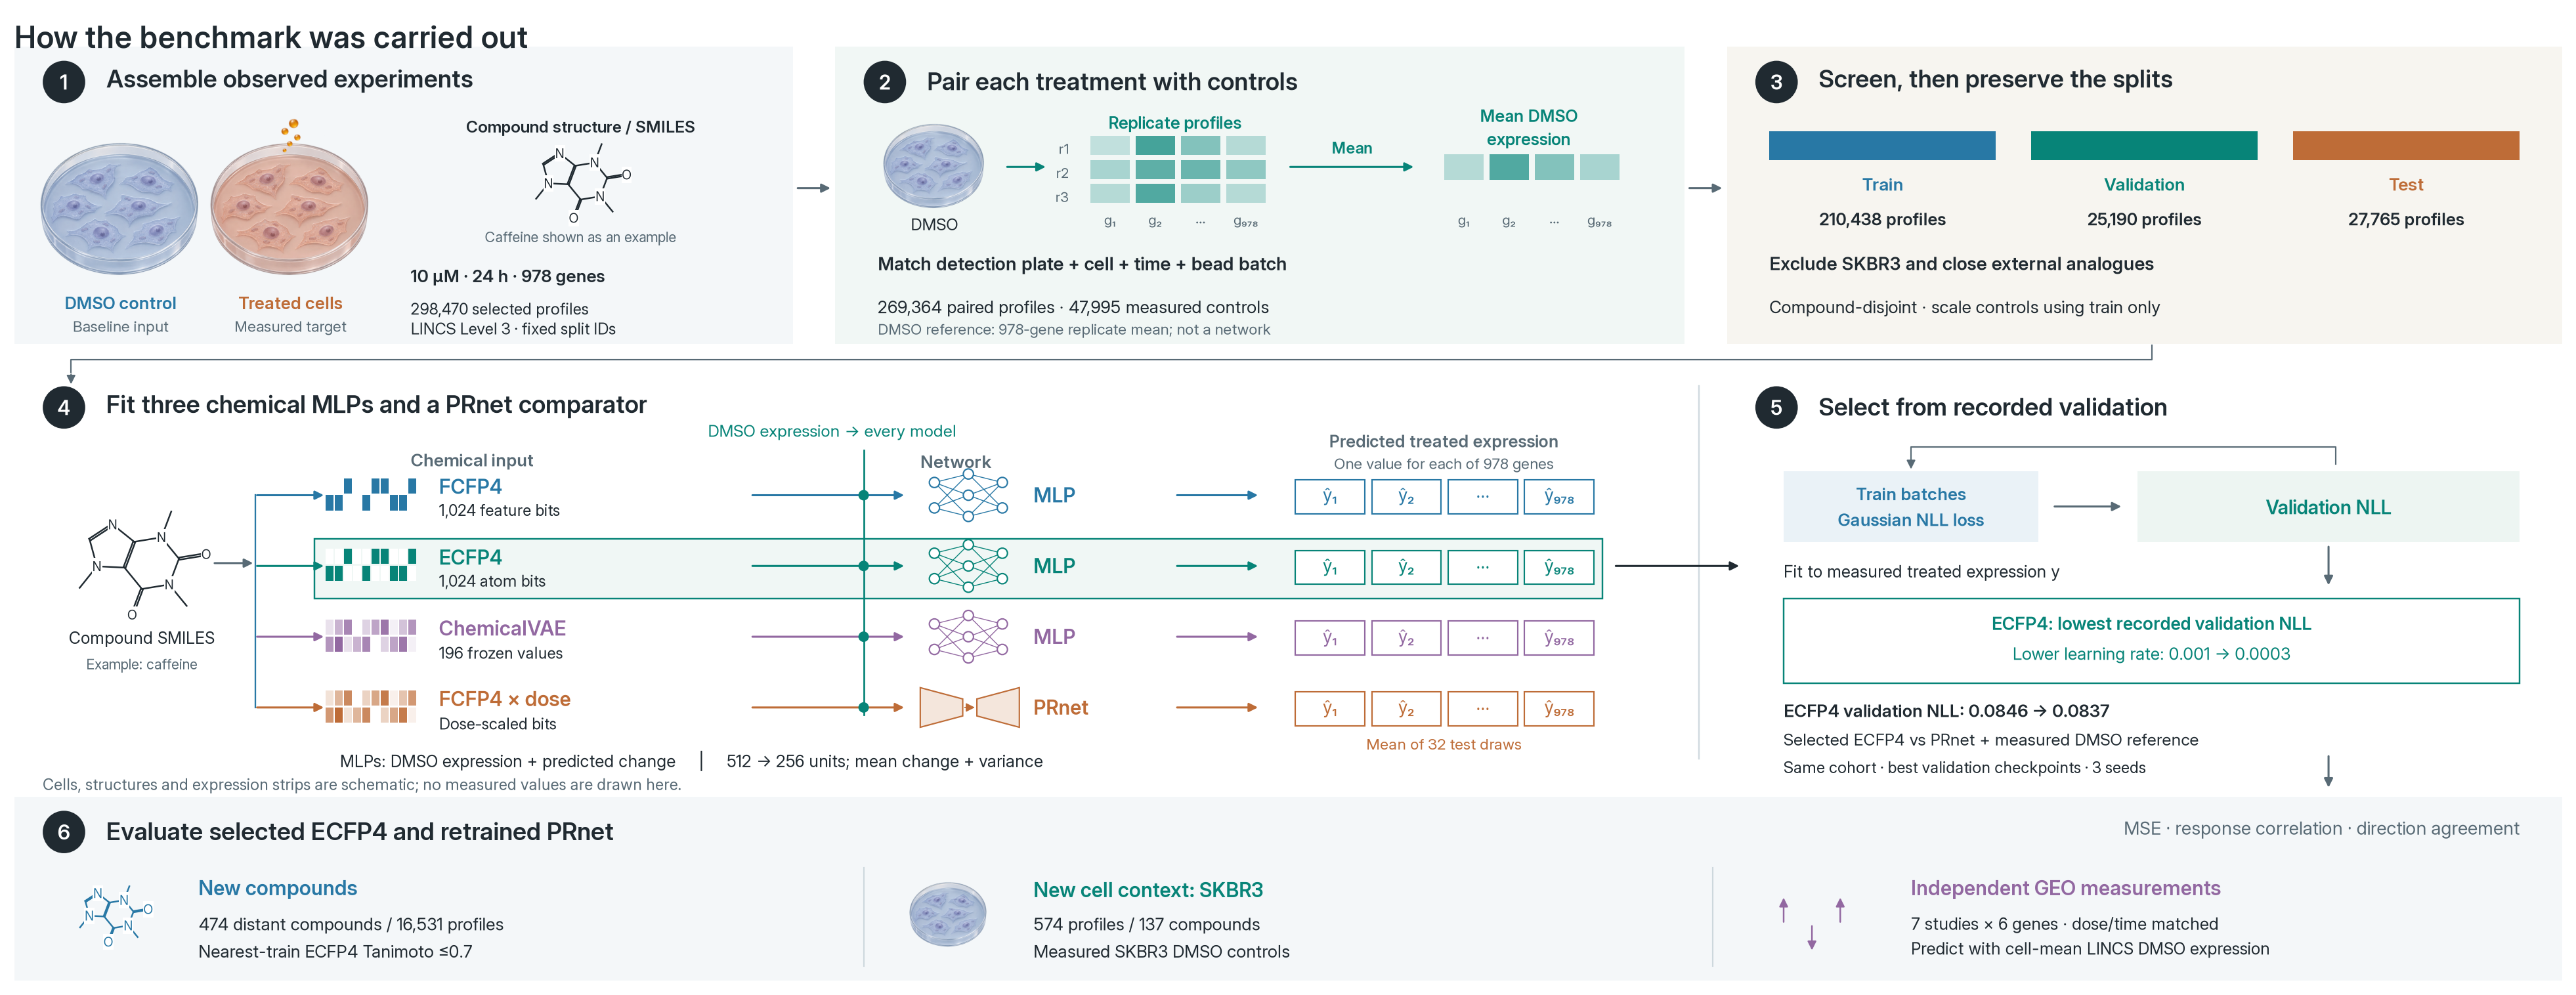

In [3]:
display(Image(filename=str(PROJECT / 'presentation/figures/pipeline.png'), width=1100))

**Figure 1.** Common data preparation, chemical encoding, validation selection and evaluation. Replicate rows share gene columns; averaging them gives the DMSO input. Each model predicts one treated-expression value per landmark gene. The dishes and feature patterns are illustrations; numerical counts come from the saved audit.

## 2. Compare three representations, select and refine

FCFP4 describes local functional classes, ECFP4 describes local atom environments, and ChemicalVAE supplies a frozen 196-value representation. FCFP4 and ECFP4 each have 1,024 bits and radius 2. Each enters a separate multilayer perceptron with measured DMSO expression.

The MLP mean is `DMSO expression + predicted change`. Its hidden layers contain 512 and 256 units; a positive variance head supports Gaussian negative log likelihood (NLL). The response head starts at zero. PRnet uses its published network classes, dose-scaled FCFP4 and decoder noise; its test mean averages 32 fixed draws.

The three MLPs are first compared at the common default setting using seed-42 validation NLL. NLL evaluates the predicted mean and variance; its ranking is specific to this criterion. Three AdamW settings were actually evaluated in parallel for each representation. Their selected settings use seeds 42, 43 and 44, with every checkpoint selected by validation NLL. PRnet is retrained with the same grid; this does not reproduce its original published numerical scores.

The next cell derives the preferred representation directly from the default validation rows. ECFP4 has the lowest recorded value (0.08465), and its lower-learning-rate setting reduces it to 0.08372. The representations were tuned in parallel; ECFP4 is identified here from the recorded validation scores. Test scores are not used for the designation; all representation results remain archived.

Validation-preferred MLP: ECFP4 MLP
Selected refinement: lower_lr


,model,val_nll,best_epoch
3,Residual,0.084649,7
0,ResidualFCFP4,0.108004,2
6,ResidualChemicalVAE,0.110533,4


,model,setting,val_nll,best_epoch,selected
3,Residual,default,0.084649,7,False
4,Residual,lower_lr,0.083725,7,True
5,Residual,lower_decay,0.092873,2,False


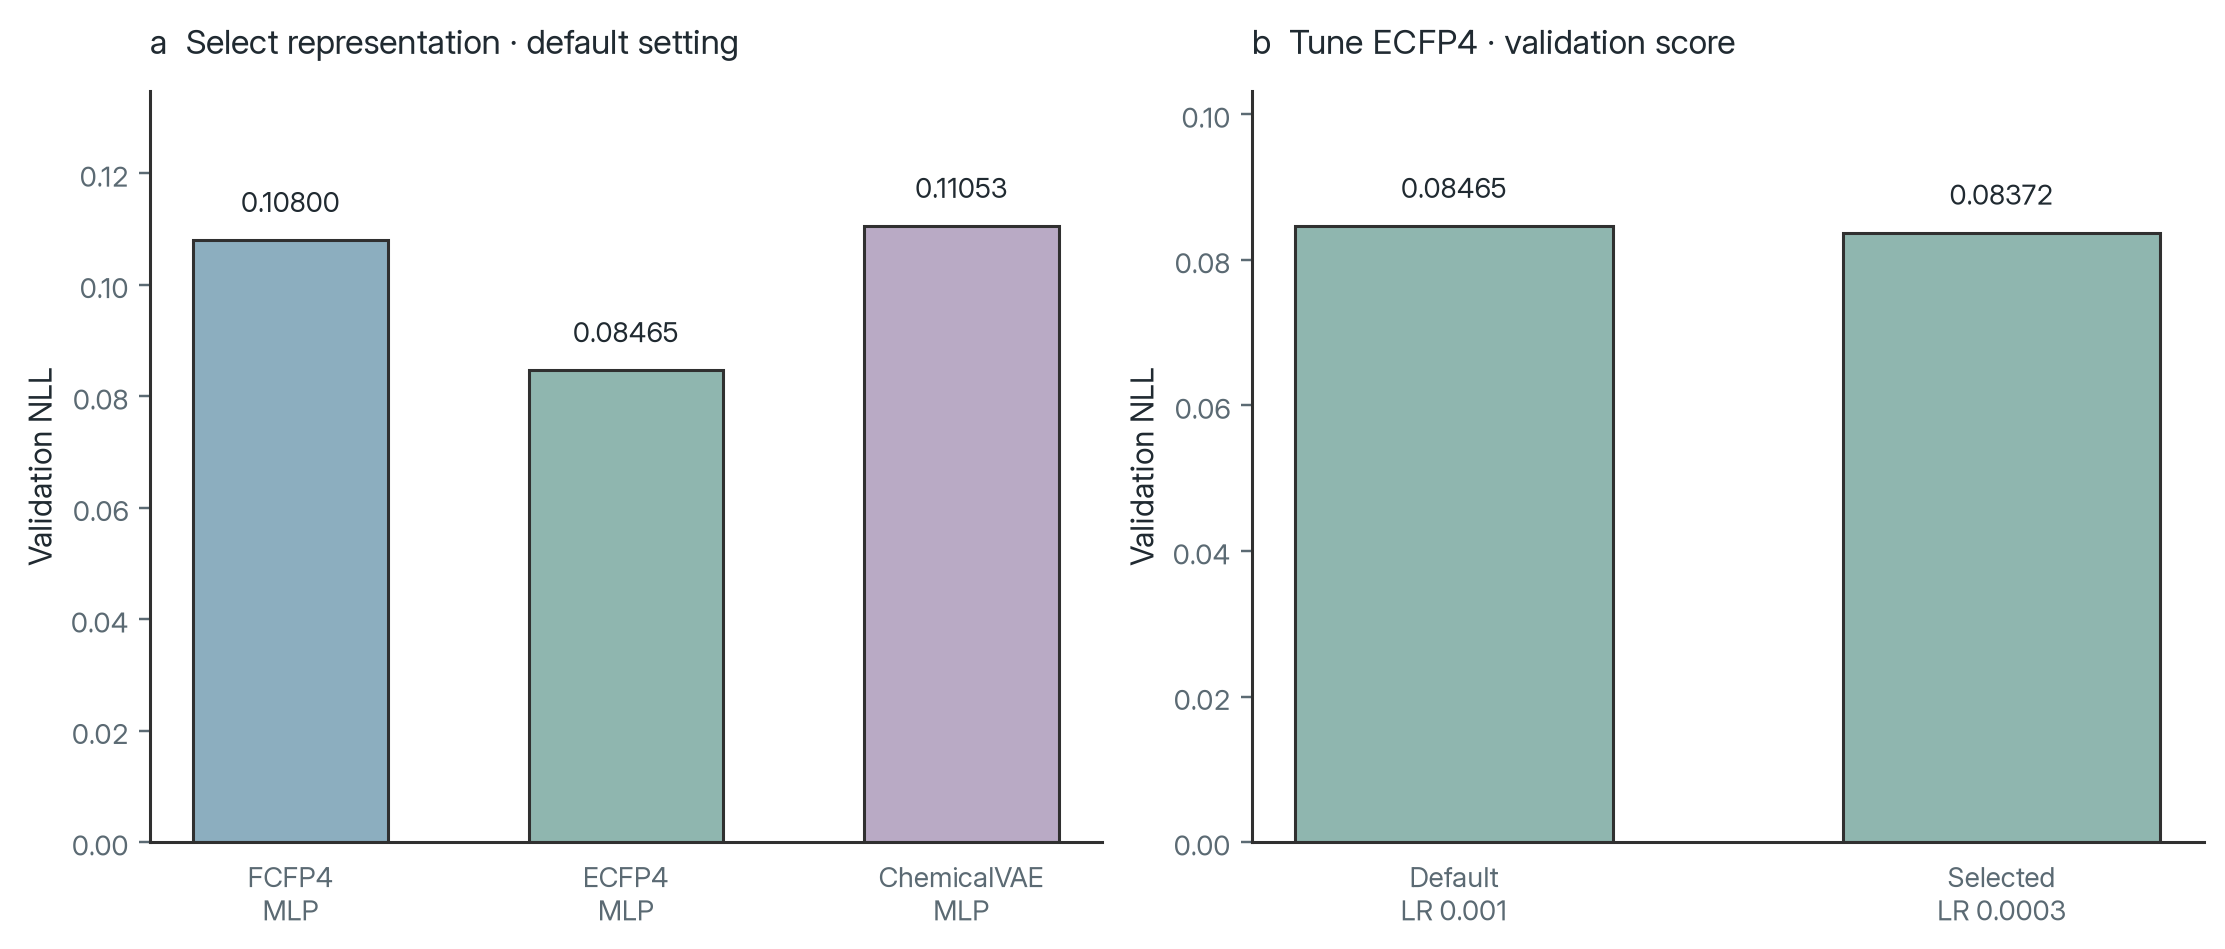

,setting,validation_nll_seed42,skbr3_mse_mean,external_correct_mean_out_of_42
0,Default,0.084649,0.580260,26.333333
1,Refined,0.083725,0.653728,24.333333


In [4]:
selected = json.loads((BALANCED / 'selected_settings.json').read_text())
tuning = pd.read_csv(BALANCED / 'tuning_validation.csv')
candidate_scores = tuning.loc[
    tuning.model.isin(MLP_CANDIDATES) & tuning.setting.eq('default')
].copy()
assert len(candidate_scores) == 3 and candidate_scores.model.is_unique
winner = candidate_scores.loc[candidate_scores.val_nll.idxmin(), 'model']
winner_setting = selected[winner]
assert winner == 'Residual', 'The current report figures require ECFP4 as validation winner.'
display(candidate_scores[['model','val_nll','best_epoch']].sort_values('val_nll'))
print('Validation-preferred MLP:', NAMES[winner])
print('Selected refinement:', winner_setting)
display(tuning.loc[tuning.model.eq(winner)].assign(
    selected=lambda frame: frame.setting.eq(winner_setting)))
display(Image(filename=str(PROJECT / 'presentation/figures/model_selection.png'), width=1100))

summary = pd.read_csv(BALANCED / 'summary/model_summary.csv')
external_all = pd.read_csv(BALANCED / 'summary/external_seed_counts.csv')
before_after = []
for phase, label, setting_name in [('fixed','Default','default'),
                                  ('tuned','Refined',winner_setting)]:
    evaluation = summary.loc[summary.model.eq(winner) & summary.phase.eq(phase)
                             & summary.dataset.eq('skbr3')].iloc[0]
    val_nll = tuning.loc[tuning.model.eq(winner) & tuning.setting.eq(setting_name),
                        'val_nll'].iloc[0]
    ext_count = external_all.loc[external_all.model.eq(winner)
                                & external_all.phase.eq(phase), 'sum'].mean()
    before_after.append({'setting':label, 'validation_nll_seed42':val_nll,
                         'skbr3_mse_mean':evaluation.mse_mean,
                         'external_correct_mean_out_of_42':ext_count})
display(pd.DataFrame(before_after))

**Figure 2.** Default-setting validation NLL for three MLPs (left), followed by default versus refined ECFP4 (right). Each value is the best checkpoint score from seed 42, not a test result or an average of biological replicates. No uncertainty bars are assigned to these single-run selection values.

The refinement lowers learning rate from 0.001 to 0.0003 at weight decay 0.01. Validation NLL improves, but ECFP4's mean SKBR3 MSE worsens from 0.5803 to 0.6537 and its external count falls from 26.3 to 24.3 out of 42. The final comparison keeps the validation-selected setting. This is evidence that validation improvement does not guarantee better transfer, not a reason to select a different setting using the test.

## 3. Run a saved model on held-out profiles

The next cell loads eight internal test rows and the selected ECFP4 checkpoint. The model and unchanged-DMSO errors use the same target values. This is an execution example, not the headline test result. When data or checkpoints are absent from a GitHub clone, restore the full ZIP assets using `docs/DATA.md`.

In [5]:
setting = selected['Residual']
folder = BALANCED / 'weights' if setting == 'default' else BALANCED / 'tuning' / setting
required = [
    PROJECT / 'extension/split_indices.npz',
    PROJECT / 'extension/scaling.npz',
    PROJECT / 'MLP_PRnet_controls/data/sample_manifest.feather',
    PROJECT / 'MLP_PRnet_controls/prepared/indices.npz',
    PROJECT / 'MLP_PRnet_controls/data/chemical_features.npz',
    PROJECT / 'MLP_PRnet_controls/prepared/targets.npy',
    PROJECT / 'MLP_PRnet_controls/data/control_means.npy',
    folder / 'Residual_42.pt',
]
if not all(path.is_file() for path in required):
    print('Prediction example skipped: data or checkpoints are missing. '
          'Restore the assets from the full submission archive; see docs/DATA.md.')
else:
    import torch
    from benchmark import build
    from scientific_data import load_internal, infer

    torch.set_num_threads(4)
    indices = np.load(PROJECT / 'extension/split_indices.npz')['test'][:8]
    example = load_internal(indices)
    network = build('Residual')
    network.load_state_dict(torch.load(folder / 'Residual_42.pt', map_location='cpu', weights_only=True))
    prediction = infer(network, 'Residual', example['features']['ECFP4'], example['control'])
    assert prediction.shape == example['y'].shape == (8, 978)
    assert np.isfinite(prediction).all()
    display(pd.DataFrame({'sample_id': example['sample_id'],
                          'model_mse': ((prediction - example['y']) ** 2).mean(1),
                          'control_mse': ((example['control'] - example['y']) ** 2).mean(1)}))

,sample_id,model_mse,control_mse
0,LJP009_A549_24H_X3_F1B19:O01,1.222422,1.357059
1,DOSBIO001_PC3_24H_X2_B11:F14,0.318928,0.380261
2,DOSBIO002_A549_24H_X3_B12:N07,0.231667,0.265205
3,ERG015_VCAP_24H_X1_B10_DUO52HI53LO:D18,0.465171,0.512087
4,DOSBIO001_NPC_24H_X2_B12:H04,0.282788,0.299423
5,DOSBIO001_A375_24H_X2_B11:I22,0.213419,0.231702
6,DOSBIO001_A375_24H_X3_B11:O07,0.402453,0.481499
7,DOSBIO001_A549_24H_X2_B11:N22,0.294621,0.249159


## 4. Unseen compounds and the SKBR3 cell line

The main compound test contains 16,531 profiles for 474 compounds with nearest-training ECFP4 Tanimoto similarity at most 0.7. SKBR3 contains 574 profiles for 137 compounds; the cell line is excluded from training. Some SKBR3 compounds were seen in other training cell lines, so this is a cell-transfer test.

MSE is the mean squared difference between predicted and measured treated expression, averaged over genes and profiles. Lower is better. The refined ECFP4 MLP has lower MSE than PRnet in both tests. It improves on unchanged DMSO for distant compounds, but unchanged DMSO is stronger than both models on SKBR3.

,dataset,model,profiles,compounds,seeds,mse_mean,mse_seed_sd
7,skbr3,DMSO reference,574,137,1,0.568916,NaN
54,skbr3,PRnet,574,137,3,2.175858,0.441264
55,skbr3,ECFP4 MLP,574,137,3,0.653728,0.029857
59,internal_low_similarity,DMSO reference,16531,474,1,0.735658,NaN
63,internal_low_similarity,PRnet,16531,474,3,0.905493,0.040415
64,internal_low_similarity,ECFP4 MLP,16531,474,3,0.672279,0.004229


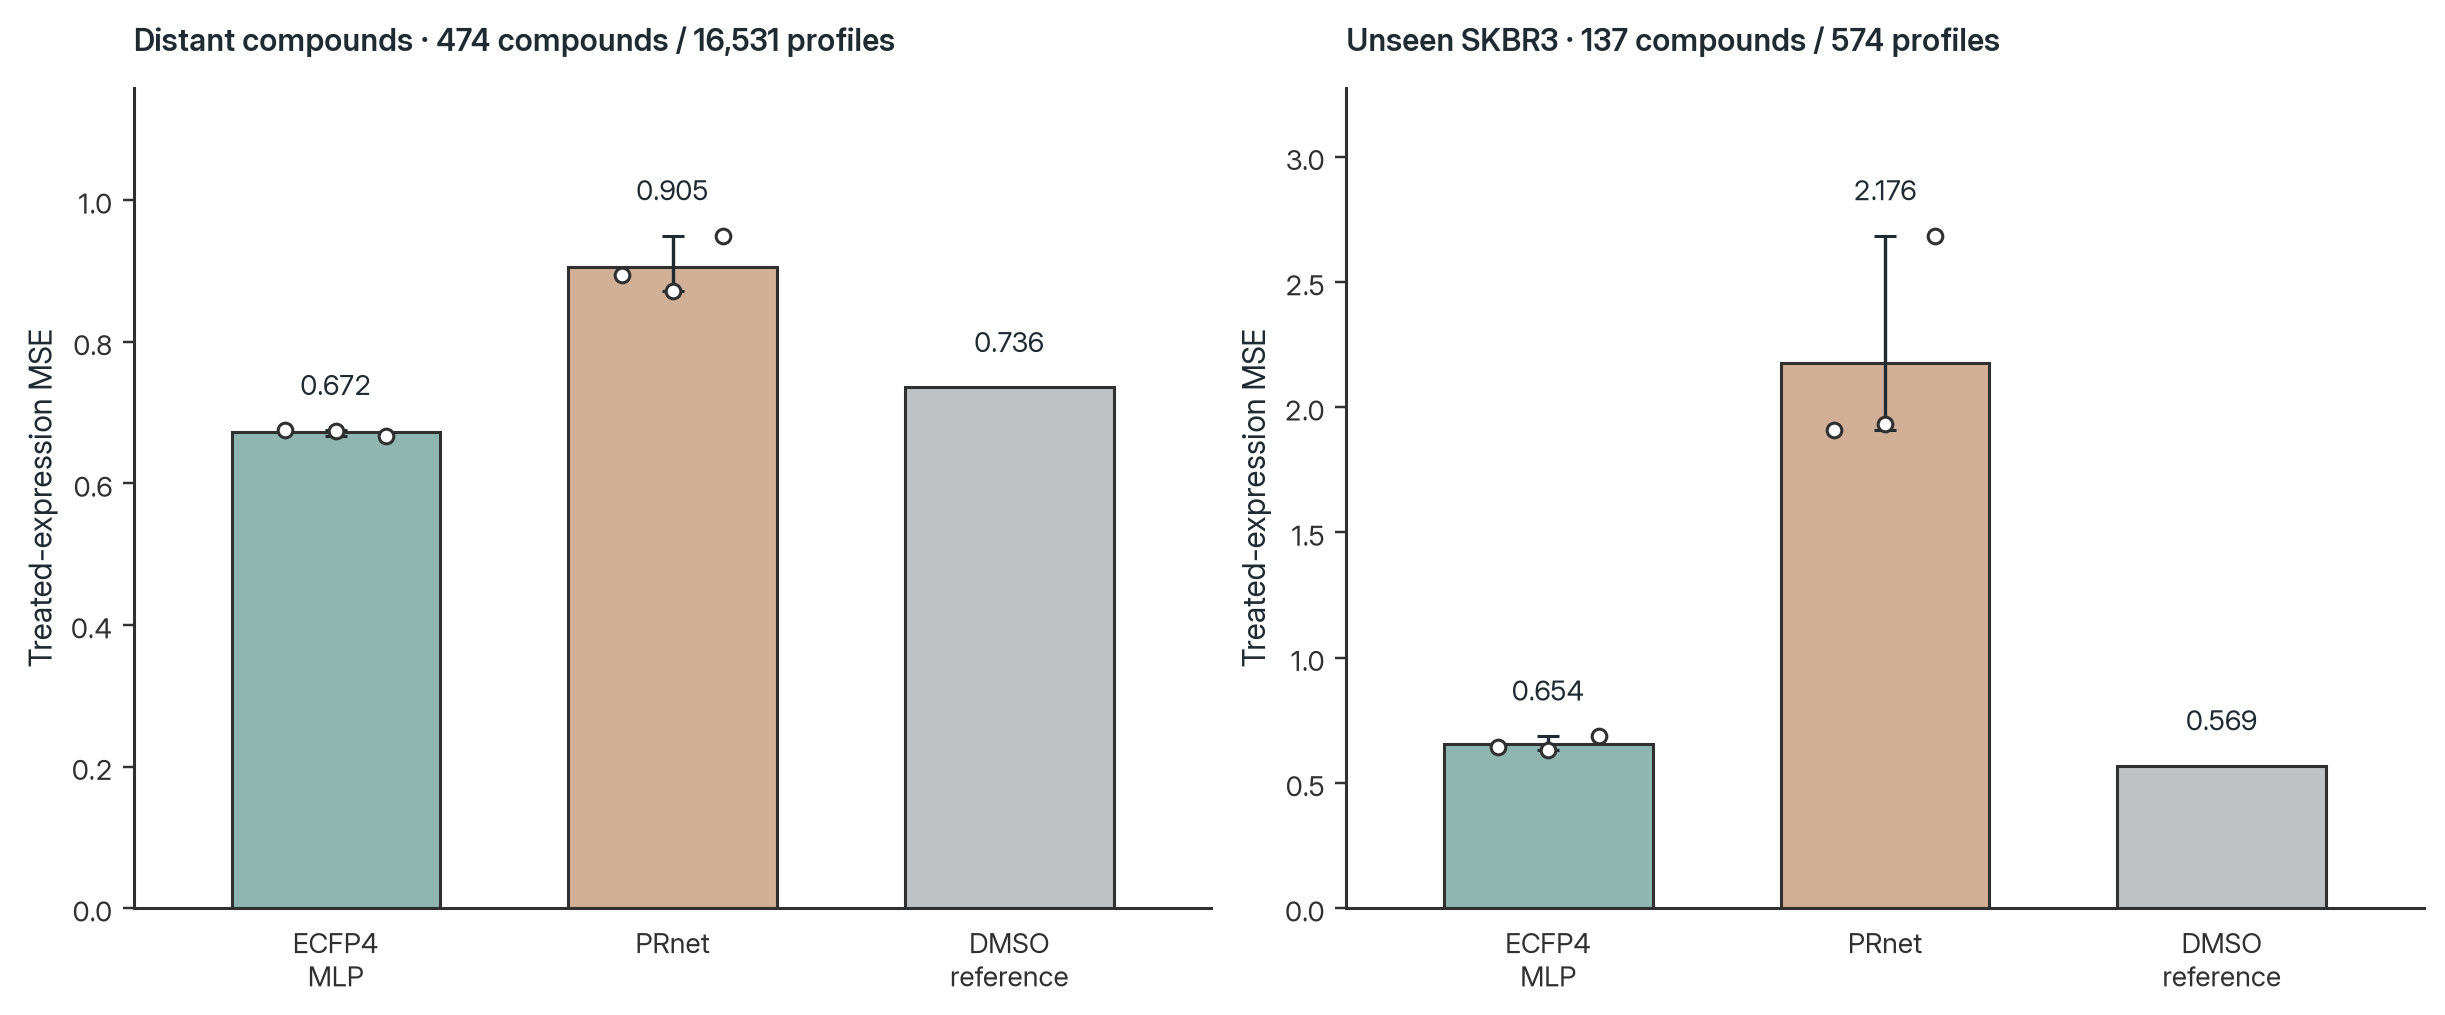

In [6]:
summary = pd.read_csv(BALANCED / 'summary/model_summary.csv')
main = summary.loc[
    ((summary.phase.eq('tuned') & summary.model.isin(SELECTED_MODELS)) |
     (summary.phase.eq('baseline') & summary.model.eq('DMSO'))) &
    summary.dataset.isin(['internal_low_similarity', 'skbr3'])
].copy()
main['model'] = main.model.map(NAMES)
display(main[['dataset','model','profiles','compounds','seeds','mse_mean','mse_seed_sd']])
display(Image(filename=str(PROJECT / 'presentation/figures/benchmark.png'), width=1100))

**Figure 3.** Treated-expression MSE on distant compounds (left) and SKBR3 (right). Bars are model means across three training runs; points are individual runs and whiskers span their minimum and maximum. The DMSO bar is one fixed no-change reference and has no training-seed error bar. Seed variation is not a confidence interval over independent biological experiments.

## 5. External regulation in six genes

Seven dose-matched GEO studies contribute 42 direction labels for AKT1, AURKB, EGFR, PIK3CA, SMAD3 and TP53. Observed signs come from GEO treated-minus-control expression. Predictions use cell-specific mean LINCS DMSO expression, not the GEO target measurements.

The unchanged-DMSO reference predicts exactly zero response, so it has no up/down prediction to score. It is intentionally absent from the direction bars. The refined ECFP4 and PRnet means are 24.3 and 23.0 correct directions out of 42. Their paired accuracy difference is 3.2 percentage points, with a descriptive study-bootstrap interval from -13.5 to +19.0 points. A clear external advantage is not established.

,model,seed,sum,size,mean
31,PRnet,42,21,42,0.500000
32,PRnet,43,24,42,0.571429
33,PRnet,44,24,42,0.571429
34,Residual,42,24,42,0.571429
35,Residual,43,24,42,0.571429
36,Residual,44,25,42,0.595238


,model,reference,cluster,difference,lower,upper,clusters
1,Residual,PRnet,GEO study,0.031746,-0.135119,0.190476,7


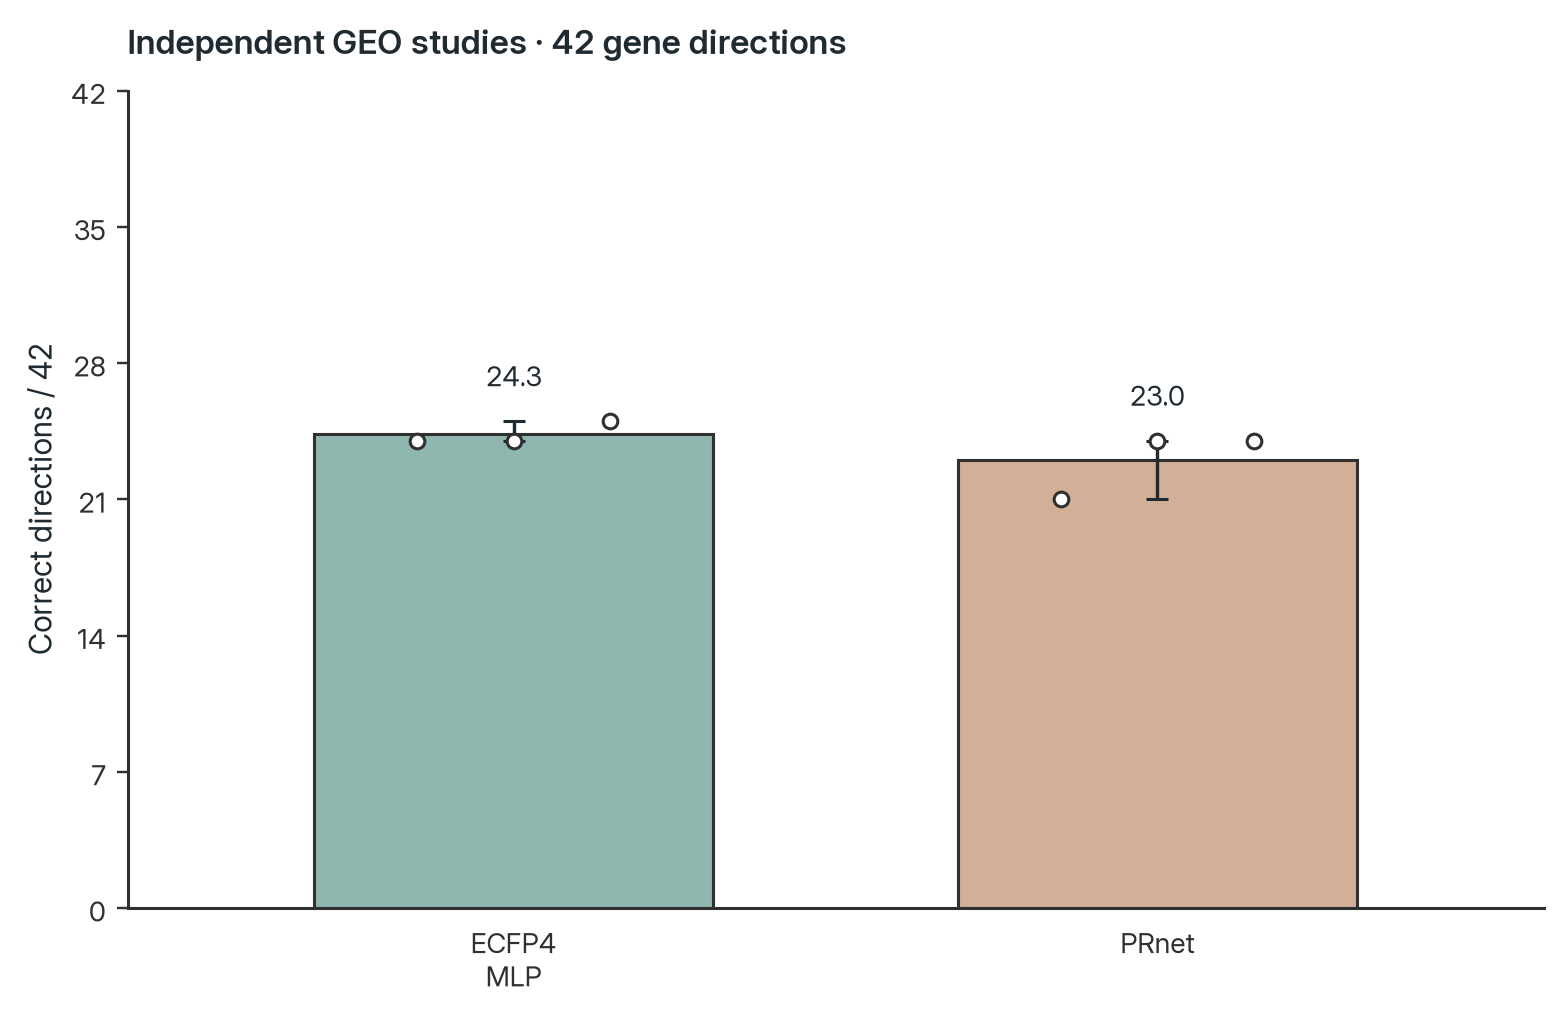

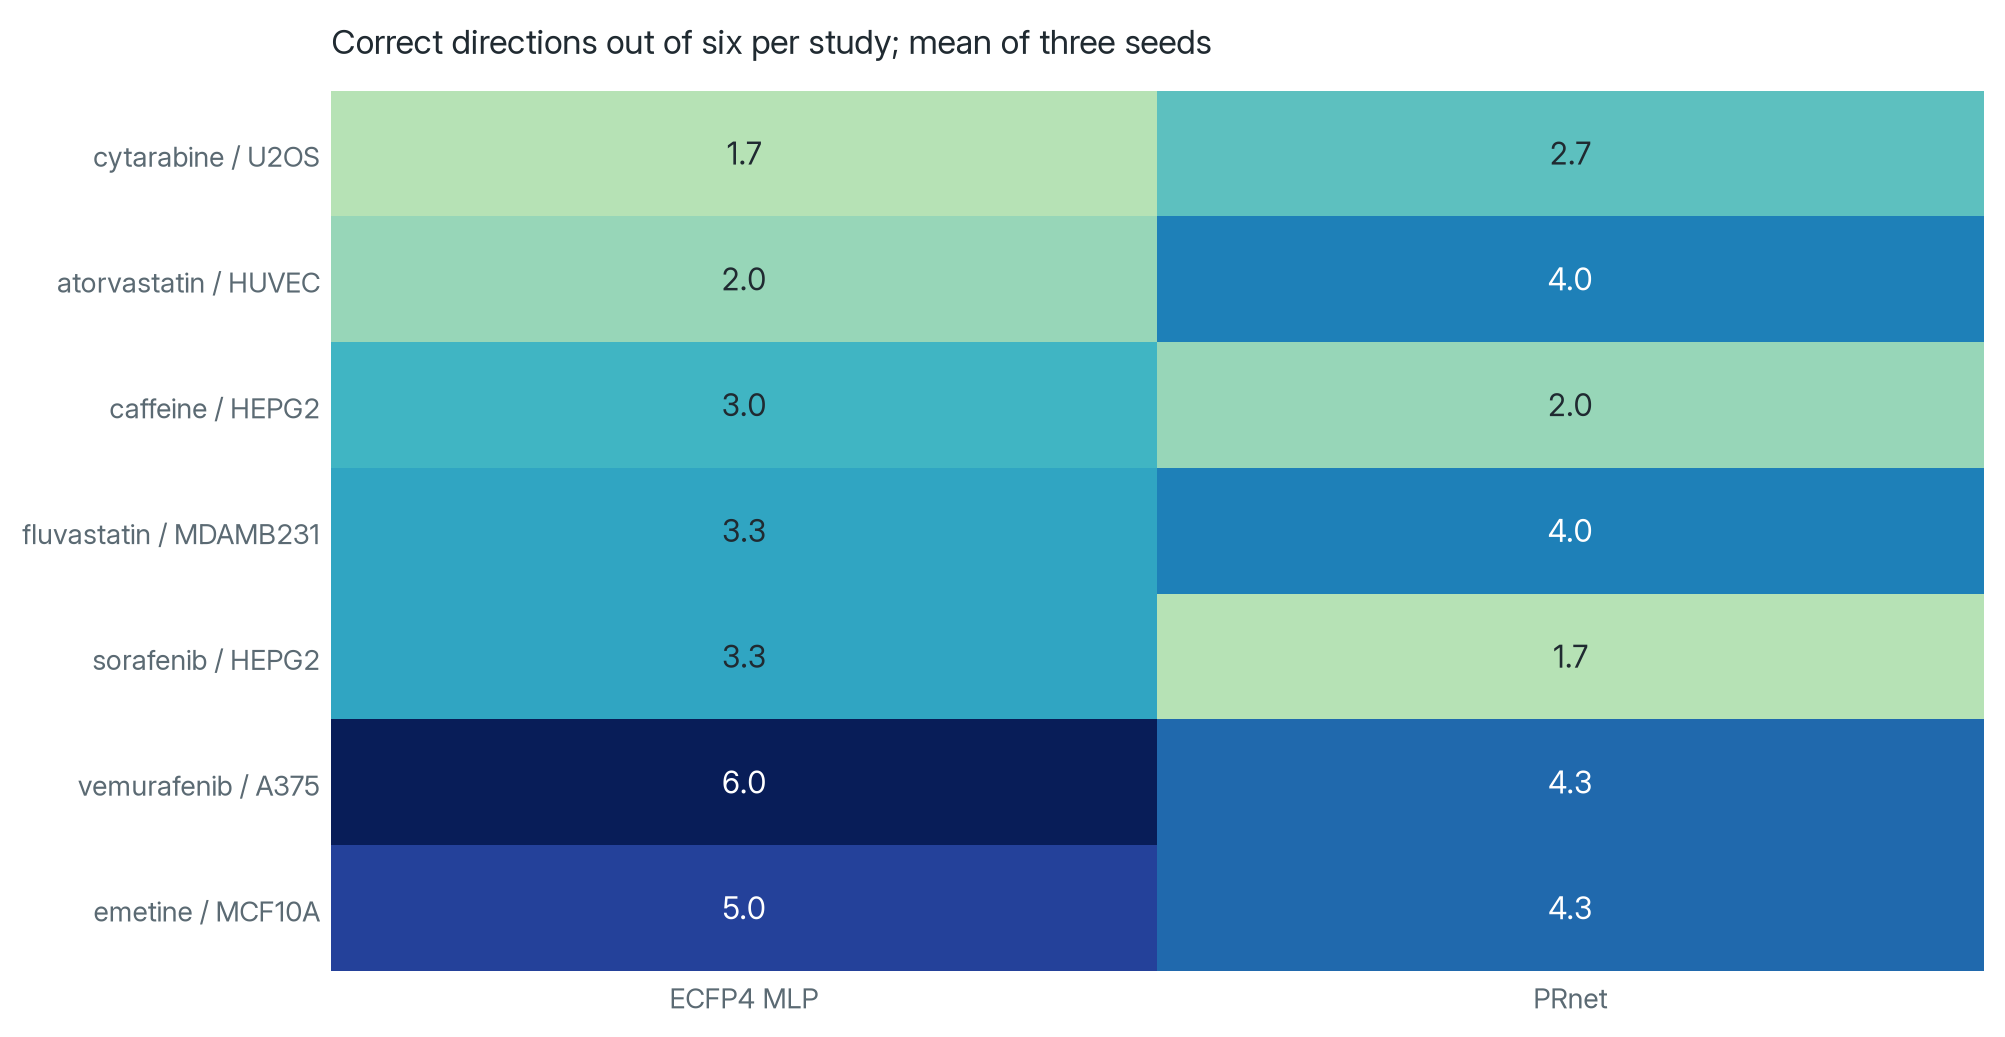

In [7]:
external = pd.read_csv(BALANCED / 'summary/external_seed_counts.csv')
external = external.loc[external.phase.eq('tuned') & external.model.isin(SELECTED_MODELS)]
display(external[['model','seed','sum','size','mean']])
intervals = pd.read_csv(BALANCED / 'summary/paired_external_intervals.csv')
display(intervals.loc[intervals.model.eq(winner) & intervals.reference.eq('PRnet')])
display(Image(filename=str(PROJECT / 'presentation/figures/external_comparison.png'), width=800))
display(Image(filename=str(PROJECT / 'presentation/figures/external_studies.png'), width=1000))

**Figure 4.** Correct regulation directions for refined ECFP4 and PRnet across seven studies and six genes. Bars, points and whiskers show the three-run mean, individual runs and range. The 42 labels are clustered within seven studies, not 42 independent experiments.

**Figure 5.** Correct directions out of six for each study, averaged across the same three runs. A cell value of 4.3 is a rounded count average, not expression or a percentage. Darker cells mean more correct signs. Only 15 of the 42 observed directions meet the descriptive clear-change rule; this is not a differential-expression significance test.

## 6. Sensitivity to DMSO-input noise

DMSO controls are measured expression profiles, so their replicate mean can contain noise. To address the project's robustness question, Gaussian noise is added to these inputs at 0, 0.25, 0.5 and 1 times each gene's within-plate DMSO replicate standard deviation. Models and measured treated targets stay fixed. Twenty technical draws are averaged at each nonzero level; these are not new biological samples.

The plot shows total SKBR3 MSE at every noise level. At zero added noise, it reproduces the clean SKBR3 scores in Figure 3. At one replicate standard deviation, ECFP4 changes from 0.6537 to 0.9928, PRnet from 2.1759 to 2.2292 and unchanged DMSO from 0.5689 to 0.8876. PRnet is less sensitive to this input perturbation but retains higher total error. The two evaluations are consistent: a smaller increase does not imply a smaller prediction error.

clean_mse       mse
model    level                     
DMSO     0.00    0.568916  0.568916
         0.25    0.568916  0.588808
         0.50    0.568916  0.648559
         1.00    0.568916  0.887634
PRnet    0.00    2.175858  2.175858
         0.25    2.175858  2.185004
         0.50    2.175858  2.196830
         1.00    2.175858  2.229234
Residual 0.00    0.653728  0.653728
         0.25    0.653728  0.674212
         0.50    0.653728  0.737677
         1.00    0.653728  0.992813

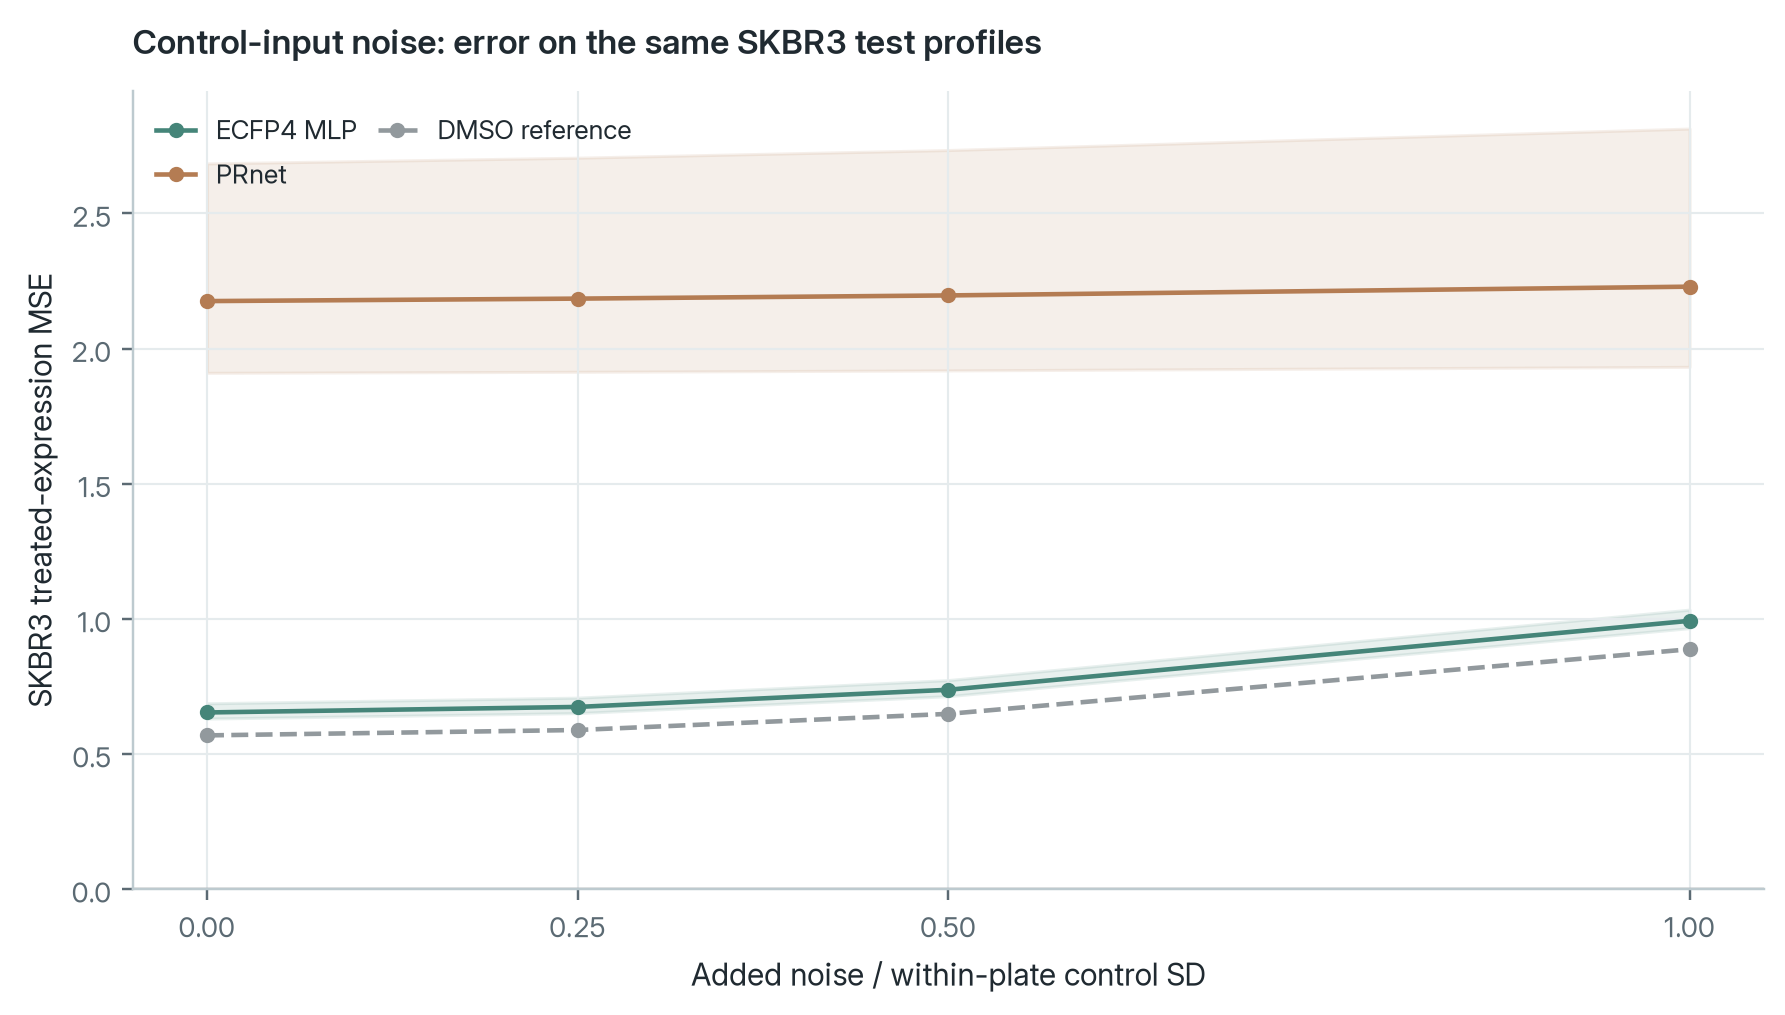

In [8]:
noise = pd.read_csv(BALANCED / 'diagnostics/noise_seed_means.csv')
noise = noise.loc[noise.model.isin(DISPLAY_MODELS)].copy()
display(noise.groupby(['model','level'])[['clean_mse','mse']].mean())
for model in DISPLAY_MODELS:
    phase = 'baseline' if model == 'DMSO' else 'tuned'
    reference = summary.loc[summary.model.eq(model) & summary.phase.eq(phase)
                            & summary.dataset.eq('skbr3'), 'mse_mean'].iloc[0]
    zero_noise = noise.loc[noise.model.eq(model) & noise.level.eq(0), 'mse'].mean()
    assert np.isclose(zero_noise, reference), 'Noise level zero must match clean SKBR3 MSE.'
display(Image(filename=str(PROJECT / 'presentation/figures/control_noise.png'), width=1000))

**Figure 6.** Total SKBR3 treated-expression MSE after perturbing DMSO inputs. Curves average selected training runs; shaded bands span their range after averaging technical draws. At zero added noise, values match the clean SKBR3 comparison. DMSO has no training seeds and no seed-range band. Models and treated targets stay fixed; this experiment does not reproduce all biological or measurement noise.

## 7. What the project establishes

- Selection: ECFP4 has the lowest default validation NLL among the three MLPs.
- Refinement: lower learning rate improves validation NLL but worsens SKBR3 and external performance.
- Unseen compounds: refined ECFP4 improves on PRnet and unchanged DMSO in the low-similarity subset.
- Unseen cell line: unchanged DMSO has lower MSE than either model on SKBR3.
- External regulation: seven studies do not resolve an ECFP4 advantage over PRnet.
- Noise: ECFP4 predictions become less accurate as DMSO inputs are perturbed.

The results do not establish a reliable compound-ranking system. Evaluation sets were reused during development, only one unseen cell line was tested, and LINCS/GEO platform differences remain. The additional baseline analyses below also limit claims that chemical encodings add value.

## 8. Reproduce the analysis

```sh
python -m pip install -r requirements.txt
python run.py figures
python run.py notebook
```

These commands rebuild plots and rerun this notebook from saved results. Prediction, verification and model fitting need the files listed in `docs/DATA.md`. With those files restored, use `python run.py check`, `python run.py evaluate` or `python run.py train --fresh`.

The report text, PDF and poster are not regenerated. Linked figures in the HTML report use the updated plots.

## Supplementary analyses

FCFP4 and ChemicalVAE test scores remain supplementary to the validation-selected comparison. Their test rankings do not determine the lead MLP. The control-only network, mean responses and linear model are additional comparisons, not experimental DMSO controls. Their results are retained because they change the interpretation: the linear baseline outperforms the chemical MLPs on distant compounds, while a training mean response performs best on SKBR3.

Further checks include chemical-input shuffling, joint compound/control-group holdout, residual-connection ablations and uncertainty calibration. See `docs/SUPPLEMENTARY_ANALYSES.md` and the report supplement for definitions, settings and limitations. The source result files are unchanged.

In [9]:
extra_models = ['ResidualFCFP4', 'ResidualChemicalVAE', 'ControlOnly',
                'GlobalMeanResponse', 'CellMeanResponse', 'RidgeECFP4']
extra = summary.loc[summary.model.isin(extra_models) & summary.phase.isin(['tuned','baseline']) & summary.dataset.isin(['internal_low_similarity','skbr3'])]
display(extra[['dataset','model','mse_mean','mse_seed_sd','response_pearson']])
permutation = pd.read_csv(BALANCED / 'diagnostics/permutation_seed_means.csv')
assert permutation.loc[permutation.model.eq('ControlOnly'),'mse_increase'].eq(0).all()
print('Chemical-shuffling negative control: passed.')

Chemical-shuffling negative control: passed.


,dataset,model,mse_mean,mse_seed_sd,response_pearson
6,skbr3,CellMeanResponse,0.550536,NaN,0.141195
8,skbr3,GlobalMeanResponse,0.550536,NaN,0.141195
9,skbr3,RidgeECFP4,1.040409,NaN,0.129468
53,skbr3,ControlOnly,0.619839,0.010609,0.123185
56,skbr3,ResidualChemicalVAE,0.600906,0.023864,0.147111
57,skbr3,ResidualFCFP4,0.610187,0.052844,0.168314
58,internal_low_similarity,CellMeanResponse,0.708047,NaN,0.144114
60,internal_low_similarity,GlobalMeanResponse,0.721456,NaN,0.106967
61,internal_low_similarity,RidgeECFP4,0.635009,NaN,0.285133
62,internal_low_similarity,ControlOnly,0.656115,0.001571,0.233209
